# Build Scenario — All Input Files

Generates **all simulation input files** from a topology-driven configuration.

**Hierarchy**

- *Brigades* → *Battalions* → CCPs + R1s
- *R2-basic*, *R2-enhanced*, and *AXPs* per brigade

Distances are given **by topology** (same-unit vs. neighbor-unit), not `(x, y)`
coordinates. Ambulance home bases: CCP→R1 ambulances at a battalion's R1;
R1→R2 ambulances at a brigade's AXP.

**Output files** (written to `data/single_run/input/`):

| Sub-path | Description |
|---|---|
| `components/distances/distance_matrix_{SUFFIX}.xlsx` | Full matrix; unreachable pairs use a large sentinel |
| `components/facilities/facilities_{SUFFIX}.xlsx` | CCP / Role1 / Role2_basic / Role2_enhanced |
| `components/units/units_{SUFFIX}.xlsx` | DCR, PEC, DCS service units |
| `components/AXPs/axp_{SUFFIX}.xlsx` | AXPs (one per brigade) |
| `components/ambulances/amb_{SUFFIX}.xlsx` | Full fleet |
| `components/c2/c2_{SUFFIX}.xlsx` | Two theater-wide C2 nodes |
| `policy_matrixes/…/facility_eligibility_{SUFFIX}_{strict,loose}.xlsx` | Patient routing |
| `policy_matrixes/…/ambulance_eligibility_{SUFFIX}_{strict,loose}.xlsx` | Ambulance routing |
| `casualty_generation_settings/military_force_structure/force_structure_{SUFFIX}.xlsx` | One row per battalion |
| `scenarios/scenario_{SUFFIX}.yaml` | Wires all of the above |

**Note on downstream code.** `facility_type` is now one of `CCP`, `Role1`,
`Role2_basic`, `Role2_enhanced`. Code that hardcoded `"Role2"` must be updated.


In [ ]:
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

In [18]:
import pathlib, yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx


# ══════════════════════════════════════════════════════════════════════════════
# ORDER OF BATTLE
# ══════════════════════════════════════════════════════════════════════════════
N_BRIGADES         = 2
N_BN_PER_BRIGADE   = 3
N_CCP_PER_BN       = 9
N_R1_PER_BN        = 1
N_R2B_PER_BRIGADE  = 0
N_R2E_PER_BRIGADE  = 2
N_AXP_PER_BRIGADE  = 1
PAR_PER_BATTALION  = 1000

# Neighbour topology: True = edge units wrap to the opposite edge.
TOROIDAL           = False

# ══════════════════════════════════════════════════════════════════════════════
# DISTANCES (km) — 3-tier ring-distance schema
# ══════════════════════════════════════════════════════════════════════════════
# Every pair not covered by a tier below stays `inf` (i.e. NaN on export) and
# any dispatch planning across that pair raises at runtime.
#
# Ring classification for two units at positions i, j in a ring of size N:
#   hops = min(|i-j|, N - |i-j|)   if TOROIDAL else |i-j|
#   tier: 0 = same, 1 = neighbor, >=2 = non_contig
#
# Battalion-ring tiers apply only within a single brigade (CCPs never cross
# brigades). Brigade-ring tiers apply across the top-level brigade list.
# Cross-brigade R1<->R1 is NOT tiered — one uniform value is used for every
# inter-brigade R1 pair regardless of brigade-ring distance.

# Battalion level (within a single brigade)
D_CCP_R1_SAME_BN        = 3
D_CCP_R1_NEIGHBOR_BN    = 7
D_CCP_R1_NON_CONTIG_BN  = 15
D_R1_R1_NEIGHBOR_BN     = 10
D_R1_R1_NON_CONTIG_BN   = 20

# Cross-brigade R1<->R1 (single flat value for every inter-brigade pair)
D_R1_R1_INTER_BDE       = 30

# Brigade level: R1 <-> AXP
D_R1_AXP_SAME_BDE       = 5
D_R1_AXP_NEIGHBOR_BDE   = 15
D_R1_AXP_NON_CONTIG_BDE = 30

# Brigade level: R1 <-> R2 (R2b and R2e share the same tier values)
D_R1_R2_SAME_BDE        = 12
D_R1_R2_NEIGHBOR_BDE    = 25
D_R1_R2_NON_CONTIG_BDE  = 50

# Brigade level: AXP <-> R2 (R2b and R2e share the same tier values)
D_AXP_R2_SAME_BDE       = 8
D_AXP_R2_NEIGHBOR_BDE   = 20
D_AXP_R2_NON_CONTIG_BDE = 40

# ══════════════════════════════════════════════════════════════════════════════
# UNITS PER MTF TYPE
# ══════════════════════════════════════════════════════════════════════════════
MTF_UNITS = {
    "Role1": [
        {"service": "DCR", "capacity": 2, "time_min": 15,  "time_max": 25},
        {"service": "PEC", "capacity": 2, "time_min": 15,  "time_max": 25},
    ],
    "Role2_basic": [
        {"service": "DCS", "capacity": 2,
         "mild_mean":   93.9, "mild_std":    41.3,
         "severe_mean": 180.0, "severe_std":  83.0},
    ],
    "Role2_enhanced": [
        {"service": "DCS", "capacity": 6,
         "mild_mean":   93.9, "mild_std":    41.3,
         "severe_mean": 180.0, "severe_std":  83.0},
    ],
}

# ══════════════════════════════════════════════════════════════════════════════
# AMBULANCES — three independent fleets
# ══════════════════════════════════════════════════════════════════════════════
# Fleet 1 — R1-homed, serving CCP → R1          (dispatched by C2_CCP_R1)
# Fleet 2 — R1-homed, serving R1  → R2          (dispatched by C2_R1_R2)
# Fleet 3 — AXP-homed, serving R1 → R2          (dispatched by C2_R1_R2)
# Each fleet is parameterised independently: count + speed + t1_t2 capacity
# + t3 capacity. Fleet size is "per parent" (battalion for R1-homed fleets,
# brigade for the AXP-homed fleet) and round-robins across the parent's
# home bases when there is more than one.

# Fleet 1 — R1-homed ambulances serving CCPs
N_R1_AMBS_FOR_CCP_PER_BN   = 2
R1_AMB_CCP_T1T2_CAPACITY   = 2
R1_AMB_CCP_T3_CAPACITY     = 3
R1_AMB_CCP_SPEED_KMH       = 30

# Fleet 2 — R1-homed ambulances serving R1 → R2
N_R1_AMBS_FOR_R2_PER_BN    = 2
R1_AMB_R2_T1T2_CAPACITY    = 2
R1_AMB_R2_T3_CAPACITY      = 3
R1_AMB_R2_SPEED_KMH        = 30

# Fleet 3 — AXP-homed ambulances serving R1 → R2
N_AXP_AMBS_FOR_R2_PER_BDE  = 4
AXP_AMB_R2_T1T2_CAPACITY   = 2
AXP_AMB_R2_T3_CAPACITY     = 3
AXP_AMB_R2_SPEED_KMH       = 30

# ══════════════════════════════════════════════════════════════════════════════
# OUTPUT & SCENARIO
# ══════════════════════════════════════════════════════════════════════════════
OUT_BASE             = paths.SINGLE_RUN_INPUT
SUFFIX               = "demonstration"
CASUALTY_CONFIG      = f"config_{SUFFIX}"      # external YAML for rates/schedule
SCENARIO_NAME        = f"scenario_{SUFFIX}"
SCENARIO_DESCRIPTION = "test demonstration"
SEED                 = 42
SIM_TILL_MIN         = 60 * 24 * 5             # 5 simulated days
DISPATCH_POLICY      = "greedy"
DATA_COLLECTOR_INTERVAL = 10.0

In [19]:
# ══════════════════════════════════════════════════════════════════════════════
# ORDER OF BATTLE
# ══════════════════════════════════════════════════════════════════════════════
N_BRIGADES         = 2
N_BN_PER_BRIGADE   = 3
N_CCP_PER_BN       = 9
N_R1_PER_BN        = 1
N_R2B_PER_BRIGADE  = 0
N_R2E_PER_BRIGADE  = 2
N_AXP_PER_BRIGADE  = 1
PAR_PER_BATTALION  = 1000

# Neighbour topology: True = edge units wrap to the opposite edge.
TOROIDAL           = False

# ══════════════════════════════════════════════════════════════════════════════
# DISTANCES (km) — 3-tier ring-distance schema
# ══════════════════════════════════════════════════════════════════════════════
# Every pair not covered by a tier below stays `inf` (i.e. NaN on export) and
# any dispatch planning across that pair raises at runtime.
#
# Ring classification for two units at positions i, j in a ring of size N:
#   hops = min(|i-j|, N - |i-j|)   if TOROIDAL else |i-j|
#   tier: 0 = same, 1 = neighbor, >=2 = non_contig
#
# Battalion-ring tiers apply only within a single brigade (CCPs never cross
# brigades). Brigade-ring tiers apply across the top-level brigade list.
# Cross-brigade R1<->R1 is NOT tiered — one uniform value is used for every
# inter-brigade R1 pair regardless of brigade-ring distance.

# Battalion level (within a single brigade)
D_CCP_R1_SAME_BN        = 3
D_CCP_R1_NEIGHBOR_BN    = 7
D_CCP_R1_NON_CONTIG_BN  = 15
D_R1_R1_NEIGHBOR_BN     = 10
D_R1_R1_NON_CONTIG_BN   = 20

# Cross-brigade R1<->R1 (single flat value for every inter-brigade pair)
D_R1_R1_INTER_BDE       = 30

# Brigade level: R1 <-> AXP
D_R1_AXP_SAME_BDE       = 5
D_R1_AXP_NEIGHBOR_BDE   = 15
D_R1_AXP_NON_CONTIG_BDE = 30

# Brigade level: R1 <-> R2 (R2b and R2e share the same tier values)
D_R1_R2_SAME_BDE        = 12
D_R1_R2_NEIGHBOR_BDE    = 25
D_R1_R2_NON_CONTIG_BDE  = 50

# Brigade level: AXP <-> R2 (R2b and R2e share the same tier values)
D_AXP_R2_SAME_BDE       = 8
D_AXP_R2_NEIGHBOR_BDE   = 20
D_AXP_R2_NON_CONTIG_BDE = 40

# ══════════════════════════════════════════════════════════════════════════════
# UNITS PER MTF TYPE
# ══════════════════════════════════════════════════════════════════════════════
MTF_UNITS = {
    "Role1": [
        {"service": "DCR", "capacity": 2, "time_min": 15,  "time_max": 25},
        {"service": "PEC", "capacity": 2, "time_min": 15,  "time_max": 25},
    ],
    "Role2_basic": [
        {"service": "DCS", "capacity": 2,
         "mild_mean":   93.9, "mild_std":    41.3,
         "severe_mean": 180.0, "severe_std":  83.0},
    ],
    "Role2_enhanced": [
        {"service": "DCS", "capacity": 6,
         "mild_mean":   93.9, "mild_std":    41.3,
         "severe_mean": 180.0, "severe_std":  83.0},
    ],
}

# ══════════════════════════════════════════════════════════════════════════════
# AMBULANCES — three independent fleets
# ══════════════════════════════════════════════════════════════════════════════
# Fleet 1 — R1-homed, serving CCP → R1          (dispatched by C2_CCP_R1)
# Fleet 2 — R1-homed, serving R1  → R2          (dispatched by C2_R1_R2)
# Fleet 3 — AXP-homed, serving R1 → R2          (dispatched by C2_R1_R2)
# Each fleet is parameterised independently: count + speed + t1_t2 capacity
# + t3 capacity. Fleet size is "per parent" (battalion for R1-homed fleets,
# brigade for the AXP-homed fleet) and round-robins across the parent's
# home bases when there is more than one.

# Fleet 1 — R1-homed ambulances serving CCPs
N_R1_AMBS_FOR_CCP_PER_BN   = 2
R1_AMB_CCP_T1T2_CAPACITY   = 2
R1_AMB_CCP_T3_CAPACITY     = 3
R1_AMB_CCP_SPEED_KMH       = 30

# Fleet 2 — R1-homed ambulances serving R1 → R2
N_R1_AMBS_FOR_R2_PER_BN    = 2
R1_AMB_R2_T1T2_CAPACITY    = 2
R1_AMB_R2_T3_CAPACITY      = 3
R1_AMB_R2_SPEED_KMH        = 30

# Fleet 3 — AXP-homed ambulances serving R1 → R2
N_AXP_AMBS_FOR_R2_PER_BDE  = 4
AXP_AMB_R2_T1T2_CAPACITY   = 2
AXP_AMB_R2_T3_CAPACITY     = 3
AXP_AMB_R2_SPEED_KMH       = 30

# ══════════════════════════════════════════════════════════════════════════════
# OUTPUT & SCENARIO
# ══════════════════════════════════════════════════════════════════════════════
def _find_project_root() -> pathlib.Path:
    for _cand in [pathlib.Path.cwd().resolve(), *pathlib.Path.cwd().resolve().parents]:
        if (_cand / "data" / "single_run" / "input").is_dir():
            return _cand
    raise FileNotFoundError("could not locate data/single_run/input/ above cwd")

OUT_BASE             = _find_project_root() / "data" / "single_run" / "input"
SUFFIX               = "demonstration"
CASUALTY_CONFIG      = f"config_{SUFFIX}"      # external YAML for rates/schedule
SCENARIO_NAME        = f"scenario_{SUFFIX}"
SCENARIO_DESCRIPTION = "test demonstration"
SEED                 = 42
SIM_TILL_MIN         = 60 * 24 * 5             # 5 simulated days
DISPATCH_POLICY      = "greedy"
DATA_COLLECTOR_INTERVAL = 10.0


## Cell 2 — Hierarchical IDs

Generate IDs for brigades, battalions, CCPs, R1s, R2-basic, R2-enhanced, AXPs,
plus the reverse lookups used downstream. Battalion indices are global.


In [20]:
# ── Brigades and battalions (battalion numbering resets per brigade) ──────────
brigade_ids = [f"br{g}" for g in range(1, N_BRIGADES + 1)]
battalion_ids = []
bn_to_bde     = {}
bde_to_bns    = {bde: [] for bde in brigade_ids}

for bde in brigade_ids:
    for k in range(1, N_BN_PER_BRIGADE + 1):
        bn_id = f"{bde}_bt{k}"
        battalion_ids.append(bn_id)
        bn_to_bde[bn_id] = bde
        bde_to_bns[bde].append(bn_id)
N_BN_TOTAL = len(battalion_ids)

# ── Facilities per battalion / brigade ────────────────────────────────────────
# Battalion-level IDs embed both brigade and battalion: ccp_br1_bt1_1, r1_br1_bt1_1
ccps_of_bn = {bn: [f"ccp_{bn}_{i}" for i in range(1, N_CCP_PER_BN + 1)] for bn in battalion_ids}
r1s_of_bn  = {bn: [f"r1_{bn}_{i}"  for i in range(1, N_R1_PER_BN  + 1)] for bn in battalion_ids}

# Brigade-level IDs carry only the brigade: r2b_br1_1, r2e_br1_1, axp_br1_1
r2bs_of_bde = {bde: [f"r2b_{bde}_{i}" for i in range(1, N_R2B_PER_BRIGADE + 1)] for bde in brigade_ids}
r2es_of_bde = {bde: [f"r2e_{bde}_{i}" for i in range(1, N_R2E_PER_BRIGADE + 1)] for bde in brigade_ids}
axps_of_bde = {bde: [f"axp_{bde}_{i}" for i in range(1, N_AXP_PER_BRIGADE + 1)] for bde in brigade_ids}

# ── Reverse lookups ───────────────────────────────────────────────────────────
bde_of_ccp = {c: bn_to_bde[bn] for bn in battalion_ids for c in ccps_of_bn[bn]}
bn_of_ccp  = {c: bn            for bn in battalion_ids for c in ccps_of_bn[bn]}
bde_of_r1  = {r: bn_to_bde[bn] for bn in battalion_ids for r in r1s_of_bn[bn]}
bn_of_r1   = {r: bn            for bn in battalion_ids for r in r1s_of_bn[bn]}
bde_of_r2b = {r: bde for bde in brigade_ids for r in r2bs_of_bde[bde]}
bde_of_r2e = {r: bde for bde in brigade_ids for r in r2es_of_bde[bde]}
bde_of_axp = {a: bde for bde in brigade_ids for a in axps_of_bde[bde]}

# ── Flat lists by type ────────────────────────────────────────────────────────
all_ccps = [c for bn  in battalion_ids for c in ccps_of_bn[bn]]
all_r1s  = [r for bn  in battalion_ids for r in r1s_of_bn[bn]]
all_r2bs = [r for bde in brigade_ids   for r in r2bs_of_bde[bde]]
all_r2es = [r for bde in brigade_ids   for r in r2es_of_bde[bde]]
all_axps = [a for bde in brigade_ids   for a in axps_of_bde[bde]]

print(f"Brigades:    {N_BRIGADES:2d}   {brigade_ids}")
print(f"Battalions:  {N_BN_TOTAL:2d}   {battalion_ids}")
print(f"CCPs:        {len(all_ccps):2d}")
print(f"R1s:         {len(all_r1s):2d}")
print(f"R2 basic:    {len(all_r2bs):2d}")
print(f"R2 enhanced: {len(all_r2es):2d}")
print(f"AXPs:        {len(all_axps):2d}")


Brigades:     2   ['br1', 'br2']
Battalions:   6   ['br1_bt1', 'br1_bt2', 'br1_bt3', 'br2_bt1', 'br2_bt2', 'br2_bt3']
CCPs:        54
R1s:          6
R2 basic:     0
R2 enhanced:  4
AXPs:         2


## Cell 3 — Neighbour helper

Every battalion has up to 2 neighbours (one on each side). Edge units without
a side either wrap around (toroidal) or just have one neighbour (non-toroidal).
Identical logic at battalion and brigade level.


In [21]:
def neighbors(i: int, N: int, toroidal: bool) -> list[int]:
    """Indices of i's neighbours in a chain of N units."""
    if N <= 1:
        return []
    if N == 2:
        return [1 - i]                # toroidal has no effect here
    if toroidal:
        return [(i - 1) % N, (i + 1) % N]
    out = []
    if i > 0:     out.append(i - 1)
    if i < N - 1: out.append(i + 1)
    return out

def bn_neighbors(bn_id: str) -> list[str]:
    sibs = bde_to_bns[bn_to_bde[bn_id]]
    return [sibs[j] for j in neighbors(sibs.index(bn_id), len(sibs), TOROIDAL)]

def bde_neighbors(bde_id: str) -> list[str]:
    return [brigade_ids[j]
            for j in neighbors(brigade_ids.index(bde_id), len(brigade_ids), TOROIDAL)]

print(f"Battalion neighbours (TOROIDAL={TOROIDAL}):")
for bn in battalion_ids:
    print(f"  {bn} → {bn_neighbors(bn)}")
print(f"Brigade neighbours:")
for bde in brigade_ids:
    print(f"  {bde} → {bde_neighbors(bde)}")


Battalion neighbours (TOROIDAL=False):
  br1_bt1 → ['br1_bt2']
  br1_bt2 → ['br1_bt1', 'br1_bt3']
  br1_bt3 → ['br1_bt2']
  br2_bt1 → ['br2_bt2']
  br2_bt2 → ['br2_bt1', 'br2_bt3']
  br2_bt3 → ['br2_bt2']
Brigade neighbours:
  br1 → ['br2']
  br2 → ['br1']


## Cell 4 — Distance matrix

Initialise every pair to `inf` and the diagonal to `0`, then fill in only the
distance types that were named. Every unnamed pair stays `inf`. On export,
`inf` is written as an empty cell (NaN) so any forbidden edge that leaks
into a dispatch plan raises an error at runtime instead of silently being
treated as a finite distance.


In [22]:
all_ids = all_ccps + all_r1s + all_r2bs + all_r2es + all_axps
dist_df = pd.DataFrame(np.inf, index=all_ids, columns=all_ids, dtype=float)
for fid in all_ids:
    dist_df.loc[fid, fid] = 0.0

def _set(a: str, b: str, d: float) -> None:
    dist_df.loc[a, b] = d
    dist_df.loc[b, a] = d

# Ring-distance helpers
def ring_distance(i: int, j: int, N: int, toroidal: bool) -> int:
    raw = abs(i - j)
    return min(raw, N - raw) if toroidal else raw

def bn_hops(bn_a: str, bn_b: str):
    """Hops between two battalions in their shared brigade ring.
    Returns None if they belong to different brigades."""
    if bn_to_bde[bn_a] != bn_to_bde[bn_b]:
        return None
    sibs = bde_to_bns[bn_to_bde[bn_a]]
    return ring_distance(sibs.index(bn_a), sibs.index(bn_b), len(sibs), TOROIDAL)

def bde_hops(bde_a: str, bde_b: str) -> int:
    return ring_distance(brigade_ids.index(bde_a), brigade_ids.index(bde_b),
                         len(brigade_ids), TOROIDAL)

def _tier(k: int) -> str:
    return "same" if k == 0 else "neighbor" if k == 1 else "non_contig"

# Tier -> km lookup dicts
_D_CCP_R1 = {"same": D_CCP_R1_SAME_BN,  "neighbor": D_CCP_R1_NEIGHBOR_BN,  "non_contig": D_CCP_R1_NON_CONTIG_BN}
_D_R1_R1  = {                           "neighbor": D_R1_R1_NEIGHBOR_BN,   "non_contig": D_R1_R1_NON_CONTIG_BN}
_D_R1_AXP = {"same": D_R1_AXP_SAME_BDE, "neighbor": D_R1_AXP_NEIGHBOR_BDE, "non_contig": D_R1_AXP_NON_CONTIG_BDE}
_D_R1_R2  = {"same": D_R1_R2_SAME_BDE,  "neighbor": D_R1_R2_NEIGHBOR_BDE,  "non_contig": D_R1_R2_NON_CONTIG_BDE}
_D_AXP_R2 = {"same": D_AXP_R2_SAME_BDE, "neighbor": D_AXP_R2_NEIGHBOR_BDE, "non_contig": D_AXP_R2_NON_CONTIG_BDE}

# CCP <-> R1 (same-brigade only; CCPs never cross brigades)
for bn_a in battalion_ids:
    for bn_b in battalion_ids:
        k = bn_hops(bn_a, bn_b)
        if k is None:
            continue
        d = _D_CCP_R1[_tier(k)]
        for ccp in ccps_of_bn[bn_a]:
            for r1 in r1s_of_bn[bn_b]:
                _set(ccp, r1, d)

# R1 <-> R1 same brigade (skip k=0 — same-battalion pair is the diagonal)
for bn_a in battalion_ids:
    for bn_b in battalion_ids:
        k = bn_hops(bn_a, bn_b)
        if k is None or k == 0:
            continue
        d = _D_R1_R1[_tier(k)]
        for r1a in r1s_of_bn[bn_a]:
            for r1b in r1s_of_bn[bn_b]:
                _set(r1a, r1b, d)

# R1 <-> R1 cross brigade (flat, one value for every inter-brigade pair)
for bde_a in brigade_ids:
    for bde_b in brigade_ids:
        if bde_a == bde_b:
            continue
        own = [r for bn in bde_to_bns[bde_a] for r in r1s_of_bn[bn]]
        nbr = [r for bn in bde_to_bns[bde_b] for r in r1s_of_bn[bn]]
        for r1a in own:
            for r1b in nbr:
                _set(r1a, r1b, D_R1_R1_INTER_BDE)

# R1 <-> AXP (brigade ring)
for bde_a in brigade_ids:
    for bde_b in brigade_ids:
        d = _D_R1_AXP[_tier(bde_hops(bde_a, bde_b))]
        own_r1s = [r for bn in bde_to_bns[bde_a] for r in r1s_of_bn[bn]]
        for r1 in own_r1s:
            for axp in axps_of_bde[bde_b]:
                _set(r1, axp, d)

# R1 <-> R2 (brigade ring; R2b and R2e share the same tier values)
for bde_a in brigade_ids:
    for bde_b in brigade_ids:
        d = _D_R1_R2[_tier(bde_hops(bde_a, bde_b))]
        own_r1s = [r for bn in bde_to_bns[bde_a] for r in r1s_of_bn[bn]]
        for r1 in own_r1s:
            for r2 in r2bs_of_bde[bde_b] + r2es_of_bde[bde_b]:
                _set(r1, r2, d)

# AXP <-> R2 (brigade ring; R2b and R2e share the same tier values)
for bde_a in brigade_ids:
    for bde_b in brigade_ids:
        d = _D_AXP_R2[_tier(bde_hops(bde_a, bde_b))]
        for axp in axps_of_bde[bde_a]:
            for r2 in r2bs_of_bde[bde_b] + r2es_of_bde[bde_b]:
                _set(axp, r2, d)

finite_offdiag = int((dist_df != np.inf).sum().sum() - len(all_ids))
print(f"Distance matrix: {dist_df.shape}, {finite_offdiag} finite off-diagonal entries")
dist_df.replace(np.inf, "∞").round(1)


Distance matrix: (66, 66), 442 finite off-diagonal entries


,ccp_br1_bt1_1,ccp_br1_bt1_2,ccp_br1_bt1_3,ccp_br1_bt1_4,ccp_br1_bt1_5,ccp_br1_bt1_6,ccp_br1_bt1_7,ccp_br1_bt1_8,ccp_br1_bt1_9,ccp_br1_bt2_1,...,r1_br1_bt3_1,r1_br2_bt1_1,r1_br2_bt2_1,r1_br2_bt3_1,r2e_br1_1,r2e_br1_2,r2e_br2_1,r2e_br2_2,axp_br1_1,axp_br2_1
ccp_br1_bt1_1,0.0,∞,∞,∞,∞,∞,∞,∞,∞,∞,...,15.0,∞,∞,∞,∞,∞,∞,∞,∞,∞
ccp_br1_bt1_2,∞,0.0,∞,∞,∞,∞,∞,∞,∞,∞,...,15.0,∞,∞,∞,∞,∞,∞,∞,∞,∞
ccp_br1_bt1_3,∞,∞,0.0,∞,∞,∞,∞,∞,∞,∞,...,15.0,∞,∞,∞,∞,∞,∞,∞,∞,∞
ccp_br1_bt1_4,∞,∞,∞,0.0,∞,∞,∞,∞,∞,∞,...,15.0,∞,∞,∞,∞,∞,∞,∞,∞,∞
ccp_br1_bt1_5,∞,∞,∞,∞,0.0,∞,∞,∞,∞,∞,...,15.0,∞,∞,∞,∞,∞,∞,∞,∞,∞
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
r2e_br1_2,∞,∞,∞,∞,∞,∞,∞,∞,∞,∞,...,12.0,25.0,25.0,25.0,∞,0.0,∞,∞,8.0,20.0
r2e_br2_1,∞,∞,∞,∞,∞,∞,∞,∞,∞,∞,...,25.0,12.0,12.0,12.0,∞,∞,0.0,∞,20.0,8.0
r2e_br2_2,∞,∞,∞,∞,∞,∞,∞,∞,∞,∞,...,25.0,12.0,12.0,12.0,∞,∞,∞,0.0,20.0,8.0
axp_br1_1,∞,∞,∞,∞,∞,∞,∞,∞,∞,∞,...,5.0,15.0,15.0,15.0,8.0,8.0,20.0,20.0,0.0,∞


## Cell 5 — Visualise topology

Force-directed graph showing only the finite edges. Position has no physical
meaning — the picture is just a sanity check that the neighbour wiring looks right.


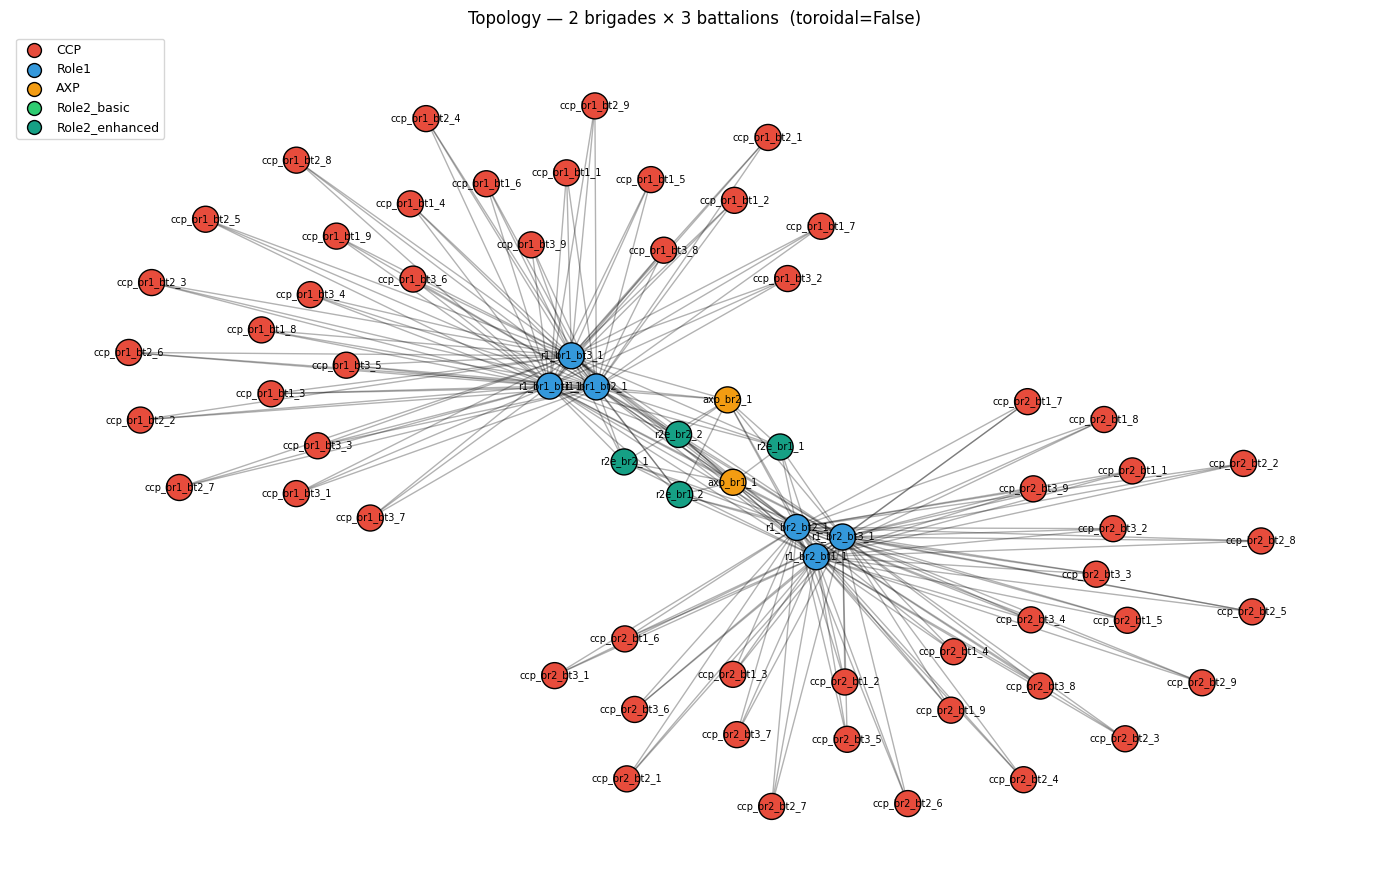

In [23]:
G = nx.Graph()
for fid in all_ids:
    G.add_node(fid)
for i, a in enumerate(all_ids):
    for b in all_ids[i + 1:]:
        d = dist_df.loc[a, b]
        if np.isfinite(d):
            G.add_edge(a, b, weight=float(d))

TYPE_OF = (
    {c: "CCP"            for c in all_ccps} |
    {r: "Role1"          for r in all_r1s}  |
    {r: "Role2_basic"    for r in all_r2bs} |
    {r: "Role2_enhanced" for r in all_r2es} |
    {a: "AXP"            for a in all_axps}
)
COLORS = {"CCP": "#e74c3c", "Role1": "#3498db", "AXP": "#f39c12",
          "Role2_basic": "#2ecc71", "Role2_enhanced": "#16a085"}
node_colors = [COLORS[TYPE_OF[n]] for n in G.nodes]

fig, ax = plt.subplots(figsize=(14, 9))
pos = nx.spring_layout(G, seed=42, k=0.8, iterations=80)
nx.draw_networkx_edges(G, pos, alpha=0.3, ax=ax)
nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=350,
                       edgecolors="black", linewidths=1, ax=ax)
nx.draw_networkx_labels(G, pos, font_size=7, ax=ax)
handles = [plt.scatter([], [], color=c, label=t, s=100, edgecolors="black")
           for t, c in COLORS.items()]
ax.legend(handles=handles, loc="upper left", fontsize=9)
ax.set_title(f"Topology — {N_BRIGADES} brigades × {N_BN_PER_BRIGADE} battalions  "
             f"(toroidal={TOROIDAL})")
ax.axis("off")
plt.tight_layout()
plt.show()


## Cell 5b — Simplified diagram with km labels

Tiered, brigade-aligned layout. Each distance class is drawn with its own
colour, and a representative edge in each class is labelled with its km
value — so every weight in the matrix is visible without cluttering the plot.


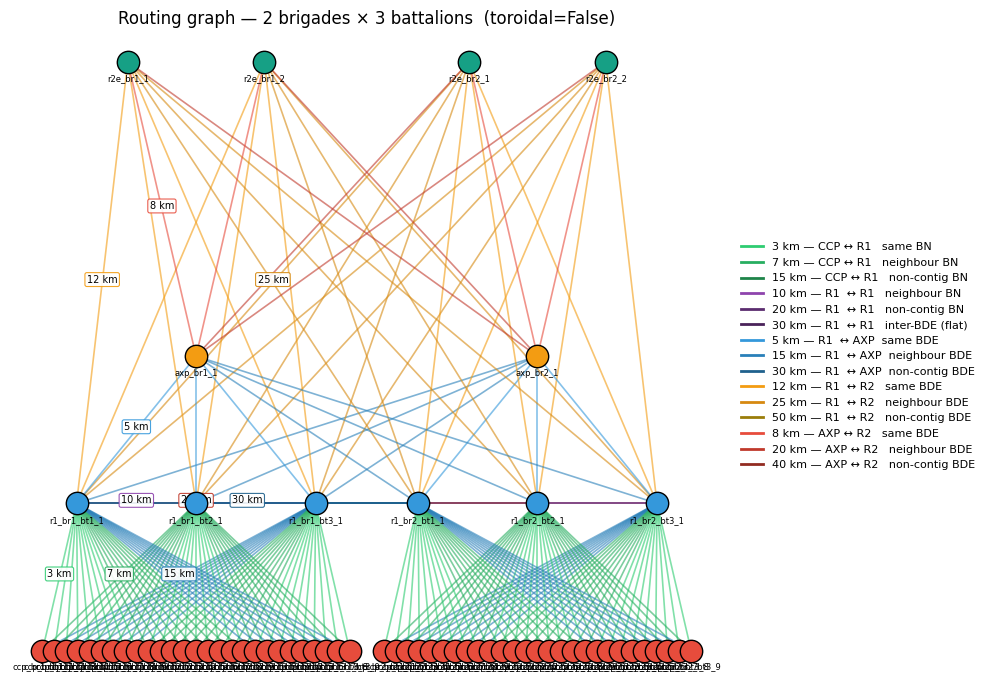

In [24]:
from matplotlib.lines import Line2D

# ── Tiered, brigade-aligned layout ────────────────────────────────────────────
TIER_Y = {"CCP": 0, "Role1": 1, "AXP": 2, "Role2_basic": 3, "Role2_enhanced": 4}
W_BDE  = max(N_CCP_PER_BN * N_BN_PER_BRIGADE, 3)   # horizontal span per brigade

_pos = {}
def _spread(ids, y, center_x, width):
    n = len(ids)
    if n == 1:
        _pos[ids[0]] = (center_x, y)
    elif n > 1:
        step = width / (n - 1)
        for i, node in enumerate(ids):
            _pos[node] = (center_x - width / 2 + i * step, y)

for bi, bde in enumerate(brigade_ids):
    cx   = bi * W_BDE
    ccps = [c for bn in bde_to_bns[bde] for c in ccps_of_bn[bn]]
    r1s  = [r for bn in bde_to_bns[bde] for r in r1s_of_bn[bn]]
    _spread(ccps,              y=TIER_Y["CCP"],            center_x=cx, width=W_BDE * 0.9)
    _spread(r1s,               y=TIER_Y["Role1"],          center_x=cx, width=W_BDE * 0.7)
    _spread(axps_of_bde[bde],  y=TIER_Y["AXP"],            center_x=cx, width=W_BDE * 0.4)
    _spread(r2bs_of_bde[bde],  y=TIER_Y["Role2_basic"],    center_x=cx, width=W_BDE * 0.4)
    _spread(r2es_of_bde[bde],  y=TIER_Y["Role2_enhanced"], center_x=cx, width=W_BDE * 0.4)

# -- Distance classes: ordered list of (description, km, colour) --------------
DIST_CLASSES = [
    # Battalion level (within a brigade)
    ("CCP ↔ R1   same BN",            D_CCP_R1_SAME_BN,        "#2ecc71"),
    ("CCP ↔ R1   neighbour BN",       D_CCP_R1_NEIGHBOR_BN,    "#27ae60"),
    ("CCP ↔ R1   non-contig BN",      D_CCP_R1_NON_CONTIG_BN,  "#1e8449"),
    ("R1  ↔ R1   neighbour BN",       D_R1_R1_NEIGHBOR_BN,     "#8e44ad"),
    ("R1  ↔ R1   non-contig BN",      D_R1_R1_NON_CONTIG_BN,   "#5b2c6f"),
    ("R1  ↔ R1   inter-BDE (flat)",   D_R1_R1_INTER_BDE,       "#4a235a"),
    # Brigade level
    ("R1  ↔ AXP  same BDE",           D_R1_AXP_SAME_BDE,       "#3498db"),
    ("R1  ↔ AXP  neighbour BDE",      D_R1_AXP_NEIGHBOR_BDE,   "#2980b9"),
    ("R1  ↔ AXP  non-contig BDE",     D_R1_AXP_NON_CONTIG_BDE, "#1f618d"),
    ("R1  ↔ R2   same BDE",           D_R1_R2_SAME_BDE,        "#f39c12"),
    ("R1  ↔ R2   neighbour BDE",      D_R1_R2_NEIGHBOR_BDE,    "#d68910"),
    ("R1  ↔ R2   non-contig BDE",     D_R1_R2_NON_CONTIG_BDE,  "#9a7d0a"),
    ("AXP ↔ R2   same BDE",           D_AXP_R2_SAME_BDE,       "#e74c3c"),
    ("AXP ↔ R2   neighbour BDE",      D_AXP_R2_NEIGHBOR_BDE,   "#c0392b"),
    ("AXP ↔ R2   non-contig BDE",     D_AXP_R2_NON_CONTIG_BDE, "#922b21"),
]
_by_weight = {round(w, 6): (label, colour) for label, w, colour in DIST_CLASSES}

NODE_COLORS = {"CCP": "#e74c3c", "Role1": "#3498db", "AXP": "#f39c12",
               "Role2_basic": "#2ecc71", "Role2_enhanced": "#16a085"}
TYPE_OF = (
    {c: "CCP"            for c in all_ccps} |
    {r: "Role1"          for r in all_r1s}  |
    {r: "Role2_basic"    for r in all_r2bs} |
    {r: "Role2_enhanced" for r in all_r2es} |
    {a: "AXP"            for a in all_axps}
)

fig, ax = plt.subplots(figsize=(max(10, 4 * N_BRIGADES), 7))

# Draw edges, colouring by distance class. Label one representative per class.
labeled_classes = set()
for i, a in enumerate(all_ids):
    for b in all_ids[i + 1:]:
        d = dist_df.loc[a, b]
        if not np.isfinite(d):
            continue
        key = round(float(d), 6)
        _, colour = _by_weight.get(key, ("?", "#cccccc"))
        (ax_, ay_), (bx_, by_) = _pos[a], _pos[b]
        ax.plot([ax_, bx_], [ay_, by_], "-", color=colour, lw=1.2, alpha=0.6, zorder=1)
        if key not in labeled_classes:
            labeled_classes.add(key)
            mx, my = (ax_ + bx_) / 2, (ay_ + by_) / 2
            ax.annotate(f"{d:g} km", (mx, my), fontsize=7, ha="center",
                        bbox=dict(boxstyle="round,pad=0.2", fc="white",
                                  ec=colour, lw=0.8, alpha=0.9),
                        zorder=3)

# Draw nodes
for fid, (x, y) in _pos.items():
    ft = TYPE_OF[fid]
    ax.scatter(x, y, color=NODE_COLORS[ft], s=260, edgecolors="black",
               linewidths=1, zorder=4)
    ax.annotate(fid, (x, y), xytext=(0, -14), textcoords="offset points",
                fontsize=6, ha="center", zorder=5)

# Tier labels on the left margin
xmin = min(x for x, _ in _pos.values())
for label, y in TIER_Y.items():
    ax.annotate(label, (xmin - W_BDE * 0.6, y), fontsize=9, fontweight="bold",
                ha="right", va="center", color="#555")

# Legend
legend_handles = [Line2D([0], [0], color=c, lw=2, label=f"{w:g} km — {lbl}")
                  for lbl, w, c in DIST_CLASSES]
ax.legend(handles=legend_handles, loc="center left",
          bbox_to_anchor=(1.01, 0.5), fontsize=8, frameon=False)

ax.set_title(f"Routing graph — {N_BRIGADES} brigades × {N_BN_PER_BRIGADE} "
             f"battalions  (toroidal={TOROIDAL})")
ax.set_xticks([]); ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(False)
plt.tight_layout()
plt.show()


## Cell 6 — Simulation tables

Build DataFrames for facilities, AXPs, units, ambulances, C2 nodes, and force
structure from the IDs and the MTF spec.


In [25]:
# ── Facilities (CCP, Role1, Role2_basic, Role2_enhanced; AXPs live elsewhere) ─
facility_rows = []
for ccp in all_ccps:
    facility_rows.append({"facility_id": ccp, "facility_type": "CCP",
                          "c2_up_id": "C2_CCP_R1",
                          "unload_policy": "unload_planned", "load_policy": "load_planned"})
for r1 in all_r1s:
    facility_rows.append({"facility_id": r1, "facility_type": "Role1",
                          "c2_up_id": "C2_R1_R2",
                          "unload_policy": "unload_planned", "load_policy": "load_planned"})
for r2b in all_r2bs:
    facility_rows.append({"facility_id": r2b, "facility_type": "Role2_basic",
                          "c2_up_id": None,
                          "unload_policy": "unload_planned", "load_policy": "load_planned"})
for r2e in all_r2es:
    facility_rows.append({"facility_id": r2e, "facility_type": "Role2_enhanced",
                          "c2_up_id": None,
                          "unload_policy": "unload_planned", "load_policy": "load_planned"})
sim_fac_df   = pd.DataFrame(facility_rows)
sim_fac_ids  = sim_fac_df["facility_id"].tolist()
fac_type_map = dict(zip(sim_fac_df["facility_id"], sim_fac_df["facility_type"]))

# ── AXPs ──────────────────────────────────────────────────────────────────────
# Always give the frame its expected columns, even if there are zero AXPs, so
# the downstream loader can still do `axp_df["axp_id"].str.lower()` safely.
axp_rows = []
for bde in brigade_ids:
    same_r1s = [r for bn in bde_to_bns[bde] for r in r1s_of_bn[bn]]
    for axp in axps_of_bde[bde]:
        axp_rows.append({"axp_id": axp, "assigned_facility_ids": ",".join(same_r1s)})
axp_df = pd.DataFrame(axp_rows, columns=["axp_id", "assigned_facility_ids"])

# ── Coordinates (tiered layout, brigade-aligned) ─────────────────────────────
# Pure visualisation hint for network.png / videos — positions are *not* used
# by the simulation (the simulation uses the distance matrix). This is the same
# tiered layout as the cell-13 diagram: CCPs on the bottom tier, then Role 1,
# AXP, Role 2 basic, Role 2 enhanced above, one column per brigade.
_TIER_Y = {"CCP": 0, "Role1": 1, "AXP": 2, "Role2_basic": 3, "Role2_enhanced": 4}
_Y_SCALE_KM = 20     # vertical spacing between tiers, km
_W_BDE_KM   = max(N_CCP_PER_BN * N_BN_PER_BRIGADE * 8, 40)
coord_rows  = []
def _spread_coord(ids, ft, tier, center_x, width):
    n = len(ids)
    y = _TIER_Y[ft] * _Y_SCALE_KM
    if n == 1:
        coord_rows.append({"facility_id": ids[0], "facility_type": ft, "x": center_x, "y": y})
    elif n > 1:
        step = width / (n - 1)
        for i, node in enumerate(ids):
            coord_rows.append({"facility_id": node, "facility_type": ft,
                               "x": center_x - width / 2 + i * step, "y": y})
for bi, bde in enumerate(brigade_ids):
    cx   = bi * _W_BDE_KM
    ccps = [c for bn in bde_to_bns[bde] for c in ccps_of_bn[bn]]
    r1s  = [r for bn in bde_to_bns[bde] for r in r1s_of_bn[bn]]
    _spread_coord(ccps,              "CCP",            "CCP",            cx, _W_BDE_KM * 0.9)
    _spread_coord(r1s,               "Role1",          "Role1",          cx, _W_BDE_KM * 0.7)
    _spread_coord(axps_of_bde[bde],  "AXP",            "AXP",            cx, _W_BDE_KM * 0.4)
    _spread_coord(r2bs_of_bde[bde],  "Role2_basic",    "Role2_basic",    cx, _W_BDE_KM * 0.4)
    _spread_coord(r2es_of_bde[bde],  "Role2_enhanced", "Role2_enhanced", cx, _W_BDE_KM * 0.4)
coord_df = pd.DataFrame(coord_rows, columns=["facility_id", "facility_type", "x", "y"])

# ── Units from MTF_UNITS spec ─────────────────────────────────────────────────
def _facilities_of_type(ft: str) -> list:
    return sim_fac_df.loc[sim_fac_df["facility_type"] == ft, "facility_id"].tolist()

unit_rows, uid = [], 1
for ft, specs in MTF_UNITS.items():
    for fid in _facilities_of_type(ft):
        for spec in specs:
            row = {"unit_id": f"U{uid:03d}", "facility_id": fid,
                   "service_type": spec["service"], "capacity": spec["capacity"]}
            if spec["service"] == "DCS":
                row.update({
                    "service_time_type":        "normal_by_triage",
                    "service_time_mild_mean":   spec["mild_mean"],
                    "service_time_mild_std":    spec["mild_std"],
                    "service_time_severe_mean": spec["severe_mean"],
                    "service_time_severe_std":  spec["severe_std"],
                })
            else:
                row.update({"service_time_min": spec["time_min"],
                            "service_time_max": spec["time_max"]})
            unit_rows.append(row); uid += 1
units_df = pd.DataFrame(unit_rows)

# ── Ambulances (3 fleets) ─────────────────────────────────────────────────────
amb_rows, aid = [], 1

# Fleet 1 — R1-homed, CCP → R1 (dispatched by C2_CCP_R1)
# Per battalion, round-robin across its R1s. Skip if the battalion has no R1.
for bn in battalion_ids:
    r1s = r1s_of_bn[bn]
    if not r1s:
        continue
    for k in range(N_R1_AMBS_FOR_CCP_PER_BN):
        amb_rows.append({"amb_id": f"AMB{aid:03d}", "c2_id": "C2_CCP_R1",
                         "start_loc_id":   r1s[k % len(r1s)],
                         "t1_t2_capacity": R1_AMB_CCP_T1T2_CAPACITY,
                         "t3_capacity":    R1_AMB_CCP_T3_CAPACITY,
                         "speed_kmh":      R1_AMB_CCP_SPEED_KMH})
        aid += 1

# Fleet 2 — R1-homed, R1 → R2 (dispatched by C2_R1_R2)
# Per battalion, round-robin across its R1s. Skip if the battalion has no R1.
for bn in battalion_ids:
    r1s = r1s_of_bn[bn]
    if not r1s:
        continue
    for k in range(N_R1_AMBS_FOR_R2_PER_BN):
        amb_rows.append({"amb_id": f"AMB{aid:03d}", "c2_id": "C2_R1_R2",
                         "start_loc_id":   r1s[k % len(r1s)],
                         "t1_t2_capacity": R1_AMB_R2_T1T2_CAPACITY,
                         "t3_capacity":    R1_AMB_R2_T3_CAPACITY,
                         "speed_kmh":      R1_AMB_R2_SPEED_KMH})
        aid += 1

# Fleet 3 — AXP-homed, R1 → R2 (dispatched by C2_R1_R2)
# Per brigade, round-robin across its AXPs. Skip if the brigade has no AXP
# (e.g. no Role-2 echelon in this scenario).
for bde in brigade_ids:
    axps = axps_of_bde[bde]
    if not axps:
        continue
    for k in range(N_AXP_AMBS_FOR_R2_PER_BDE):
        amb_rows.append({"amb_id": f"AMB{aid:03d}", "c2_id": "C2_R1_R2",
                         "start_loc_id":   axps[k % len(axps)],
                         "t1_t2_capacity": AXP_AMB_R2_T1T2_CAPACITY,
                         "t3_capacity":    AXP_AMB_R2_T3_CAPACITY,
                         "speed_kmh":      AXP_AMB_R2_SPEED_KMH})
        aid += 1
amb_df = pd.DataFrame(amb_rows, columns=["amb_id", "c2_id", "start_loc_id",
                                         "t1_t2_capacity", "t3_capacity", "speed_kmh"])

# ── C2 (two theater-wide nodes) ───────────────────────────────────────────────
c2_df = pd.DataFrame([
    {"c2_id": "C2_CCP_R1",
     "facility_ids":  ",".join(all_ccps),
     "ambulance_ids": ",".join(amb_df.loc[amb_df["c2_id"] == "C2_CCP_R1", "amb_id"])},
    {"c2_id": "C2_R1_R2",
     "facility_ids":  ",".join(all_r1s),
     "ambulance_ids": ",".join(amb_df.loc[amb_df["c2_id"] == "C2_R1_R2", "amb_id"])},
])

# ── Force structure (one row per battalion) ───────────────────────────────
# Per-battalion facility rosters. Column groups:
#   ccp_ids / r1_ids                       → this battalion's CCPs and R1s.
#   r2b_ids / r2e_ids / axp_ids            → this battalion's brigade's R2-basic, R2-enhanced, AXP.
#   neighbor_r1_ids                        → R1s of neighbour battalions (same brigade).
#   neighbor_r2b_ids / _r2e_ids / _axp_ids → neighbour brigades' R2b / R2e / AXP.
# BCAS spawn map is built from ccp_ids; DNBI spawn map from r1_ids.
fs_rows = []
for bn in battalion_ids:
    bde      = bn_to_bde[bn]
    nbr_bns  = bn_neighbors(bn)
    nbr_bdes = bde_neighbors(bde)
    fs_rows.append({
        "division":         "DIV1",
        "brigade":          bde.upper(),
        "battalion":        bn.upper(),
        "par":              PAR_PER_BATTALION,
        "involved":         True,
        "ccp_ids":          ",".join(ccps_of_bn[bn]),
        "r1_ids":           ",".join(r1s_of_bn[bn]),
        "r2b_ids":          ",".join(r2bs_of_bde[bde]),
        "r2e_ids":          ",".join(r2es_of_bde[bde]),
        "axp_ids":          ",".join(axps_of_bde[bde]),
        "neighbor_r1_ids":  ",".join(r for nb in nbr_bns  for r in r1s_of_bn[nb]),
        "neighbor_r2b_ids": ",".join(r for nb in nbr_bdes for r in r2bs_of_bde[nb]),
        "neighbor_r2e_ids": ",".join(r for nb in nbr_bdes for r in r2es_of_bde[nb]),
        "neighbor_axp_ids": ",".join(a for nb in nbr_bdes for a in axps_of_bde[nb]),
    })
force_df = pd.DataFrame(fs_rows)

print(f"sim_fac_df:  {len(sim_fac_df):3d} rows  {sim_fac_df['facility_type'].value_counts().to_dict()}")
print(f"axp_df:      {len(axp_df):3d} AXPs")
print(f"coord_df:    {len(coord_df):3d} rows  {coord_df['facility_type'].value_counts().to_dict()}")
print(f"units_df:    {len(units_df):3d} units  {units_df['service_type'].value_counts().to_dict()}")
print(f"amb_df:      {len(amb_df):3d} ambulances  {amb_df['c2_id'].value_counts().to_dict()}")
print(f"c2_df:       {len(c2_df):3d} C2 nodes")
print(f"force_df:    {len(force_df):3d} battalions  total PAR={force_df['par'].sum()}")


sim_fac_df:   64 rows  {'CCP': 54, 'Role1': 6, 'Role2_enhanced': 4}
axp_df:        2 AXPs
coord_df:     66 rows  {'CCP': 54, 'Role1': 6, 'Role2_enhanced': 4, 'AXP': 2}
units_df:     16 units  {'DCR': 6, 'PEC': 6, 'DCS': 4}
amb_df:       32 ambulances  {'C2_R1_R2': 20, 'C2_CCP_R1': 12}
c2_df:         2 C2 nodes
force_df:      6 battalions  total PAR=6000


## Cell 7 — Eligibility matrices

**Facility eligibility** (patient routing):
- *Strict:* CCP → R1 of same battalion; R1 → R2b/R2e of same brigade.
- *Loose:* extend to neighbour battalions / brigades respectively.

**Ambulance eligibility** (which facilities each ambulance may visit):
- CCP→R1 amb: strict = own battalion's CCPs+R1s; loose = adds neighbours' CCPs+R1s.
- R1→R2 amb: strict = own brigade's R1s+R2b+R2e; loose = adds neighbours'.


In [26]:
def make_fac_eligibility(loose: bool) -> pd.DataFrame:
    dm = pd.DataFrame(0, index=sim_fac_ids, columns=sim_fac_ids)
    for src in sim_fac_ids:
        st = fac_type_map[src]
        if st == "CCP":
            bn = bn_of_ccp[src]
            targets = [bn] + (bn_neighbors(bn) if loose else [])
            for nb in targets:
                for r1 in r1s_of_bn[nb]:
                    dm.loc[src, r1] = 1
        elif st == "Role1":
            bde = bde_of_r1[src]
            targets = [bde] + (bde_neighbors(bde) if loose else [])
            for nb in targets:
                for r in r2bs_of_bde[nb] + r2es_of_bde[nb]:
                    dm.loc[src, r] = 1
    return dm

def make_amb_eligibility(loose: bool) -> pd.DataFrame:
    amb_ids = amb_df["amb_id"].tolist()
    dm = pd.DataFrame(0, index=amb_ids, columns=sim_fac_ids)
    for _, row in amb_df.iterrows():
        aid, c2id, home = row["amb_id"], row["c2_id"], row["start_loc_id"]
        if c2id == "C2_CCP_R1":
            bn = bn_of_r1[home]
            targets = [bn] + (bn_neighbors(bn) if loose else [])
            for nb in targets:
                for f in ccps_of_bn[nb] + r1s_of_bn[nb]:
                    dm.loc[aid, f] = 1
        elif c2id == "C2_R1_R2":
            # Home base is either an AXP (fleet 3) or an R1 (fleet 2).
            bde = bde_of_axp.get(home) or bde_of_r1[home]
            targets = [bde] + (bde_neighbors(bde) if loose else [])
            for nb in targets:
                for bn in bde_to_bns[nb]:
                    for r1 in r1s_of_bn[bn]:
                        dm.loc[aid, r1] = 1
                for r in r2bs_of_bde[nb] + r2es_of_bde[nb]:
                    dm.loc[aid, r] = 1
    return dm

fac_strict = make_fac_eligibility(loose=False)
fac_loose  = make_fac_eligibility(loose=True)
amb_strict = make_amb_eligibility(loose=False)
amb_loose  = make_amb_eligibility(loose=True)
print(f"facility_eligibility:  strict {int(fac_strict.values.sum())} edges,  "
      f"loose {int(fac_loose.values.sum())} edges")
print(f"ambulance_eligibility: strict {int(amb_strict.values.sum())} edges,  "
      f"loose {int(amb_loose.values.sum())} edges")


facility_eligibility:  strict 66 edges,  loose 150 edges
ambulance_eligibility: strict 220 edges,  loose 480 edges


def _out(subpath: str) -> Path:
    p = OUT_BASE / subpath
    p.parent.mkdir(parents=True, exist_ok=True)
    return p

# Export inf as empty cells (NaN). Any forbidden leg that reaches the
# ambulance at runtime will fail the C2 dispatch-time finite-distance check.
dist_export = dist_df.replace(np.inf, np.nan).round(2)

FORCE_STRUCTURE_REL = f"casualty_generation_settings/military_force_structure/force_structure_{SUFFIX}.xlsx"

exports = [
    (_out(f"components/distances/distance_matrix_{SUFFIX}.xlsx"),
     lambda p: dist_export.to_excel(p)),
    (_out(f"components/distances/coordinates_{SUFFIX}.xlsx"),
     lambda p: coord_df.to_excel(p, index=False)),
    (_out(f"components/facilities/facilities_{SUFFIX}.xlsx"),
     lambda p: sim_fac_df.to_excel(p, index=False)),
    (_out(f"components/units/units_{SUFFIX}.xlsx"),
     lambda p: units_df.to_excel(p, index=False)),
    (_out(f"components/AXPs/axp_{SUFFIX}.xlsx"),
     lambda p: axp_df.to_excel(p, index=False)),
    (_out(f"components/ambulances/amb_{SUFFIX}.xlsx"),
     lambda p: amb_df.to_excel(p, index=False)),
    (_out(f"components/c2/c2_{SUFFIX}.xlsx"),
     lambda p: c2_df.to_excel(p, index=False)),
    (_out(f"policy_matrixes/facility_eligibility/facility_eligibility_{SUFFIX}_strict.xlsx"),
     lambda p: fac_strict.to_excel(p)),
    (_out(f"policy_matrixes/facility_eligibility/facility_eligibility_{SUFFIX}_loose.xlsx"),
     lambda p: fac_loose.to_excel(p)),
    (_out(f"policy_matrixes/ambulance_eligibility/ambulance_eligibility_{SUFFIX}_strict.xlsx"),
     lambda p: amb_strict.to_excel(p)),
    (_out(f"policy_matrixes/ambulance_eligibility/ambulance_eligibility_{SUFFIX}_loose.xlsx"),
     lambda p: amb_loose.to_excel(p)),
    (_out(FORCE_STRUCTURE_REL),
     lambda p: force_df.to_excel(p, index=False)),
]
for path, writer in exports:
    writer(path)
    print(f"  ✓ {path.relative_to(OUT_BASE)}")
print("All component files + force structure written.")

In [27]:
def _out(subpath: str) -> pathlib.Path:
    p = OUT_BASE / subpath
    p.parent.mkdir(parents=True, exist_ok=True)
    return p

# Export inf as empty cells (NaN). Any forbidden leg that reaches the
# ambulance at runtime will fail the C2 dispatch-time finite-distance check.
dist_export = dist_df.replace(np.inf, np.nan).round(2)

FORCE_STRUCTURE_REL = f"casualty_generation_settings/military_force_structure/force_structure_{SUFFIX}.xlsx"

exports = [
    (_out(f"components/distances/distance_matrix_{SUFFIX}.xlsx"),
     lambda p: dist_export.to_excel(p)),
    (_out(f"components/distances/coordinates_{SUFFIX}.xlsx"),
     lambda p: coord_df.to_excel(p, index=False)),
    (_out(f"components/facilities/facilities_{SUFFIX}.xlsx"),
     lambda p: sim_fac_df.to_excel(p, index=False)),
    (_out(f"components/units/units_{SUFFIX}.xlsx"),
     lambda p: units_df.to_excel(p, index=False)),
    (_out(f"components/AXPs/axp_{SUFFIX}.xlsx"),
     lambda p: axp_df.to_excel(p, index=False)),
    (_out(f"components/ambulances/amb_{SUFFIX}.xlsx"),
     lambda p: amb_df.to_excel(p, index=False)),
    (_out(f"components/c2/c2_{SUFFIX}.xlsx"),
     lambda p: c2_df.to_excel(p, index=False)),
    (_out(f"policy_matrixes/facility_eligibility/facility_eligibility_{SUFFIX}_strict.xlsx"),
     lambda p: fac_strict.to_excel(p)),
    (_out(f"policy_matrixes/facility_eligibility/facility_eligibility_{SUFFIX}_loose.xlsx"),
     lambda p: fac_loose.to_excel(p)),
    (_out(f"policy_matrixes/ambulance_eligibility/ambulance_eligibility_{SUFFIX}_strict.xlsx"),
     lambda p: amb_strict.to_excel(p)),
    (_out(f"policy_matrixes/ambulance_eligibility/ambulance_eligibility_{SUFFIX}_loose.xlsx"),
     lambda p: amb_loose.to_excel(p)),
    (_out(FORCE_STRUCTURE_REL),
     lambda p: force_df.to_excel(p, index=False)),
]
for path, writer in exports:
    writer(path)
    print(f"  ✓ {path.relative_to(OUT_BASE)}")
print("All component files + force structure written.")


  ✓ components\distances\distance_matrix_demonstration.xlsx
  ✓ components\distances\coordinates_demonstration.xlsx
  ✓ components\facilities\facilities_demonstration.xlsx
  ✓ components\units\units_demonstration.xlsx
  ✓ components\AXPs\axp_demonstration.xlsx
  ✓ components\ambulances\amb_demonstration.xlsx
  ✓ components\c2\c2_demonstration.xlsx
  ✓ policy_matrixes\facility_eligibility\facility_eligibility_demonstration_strict.xlsx
  ✓ policy_matrixes\facility_eligibility\facility_eligibility_demonstration_loose.xlsx
  ✓ policy_matrixes\ambulance_eligibility\ambulance_eligibility_demonstration_strict.xlsx
  ✓ policy_matrixes\ambulance_eligibility\ambulance_eligibility_demonstration_loose.xlsx
  ✓ casualty_generation_settings\military_force_structure\force_structure_demonstration.xlsx
All component files + force structure written.


## Cell 9 — Verify casualty config

Casualty *rates* and *schedule* (`bcas_rate`, `dnbi_rate`, `n_days`,
`waves_per_day`, `wave_duration_min`, diagnosis mix, prescriptions) live in
`casualty_generation_settings/sampling_settings/{CASUALTY_CONFIG}.yaml` — the
notebook does **not** generate it. Verify it exists and that its
`force_structure` path matches the file we just wrote.


In [28]:
config_rel  = f"casualty_generation_settings/sampling_settings/{CASUALTY_CONFIG}.yaml"
config_path = OUT_BASE / config_rel

if not config_path.exists():
    print(f"  ✗ Casualty config NOT found: {config_rel}")
    print(f"    Create it with at minimum:")
    print(f"       n_days, waves_per_day, wave_duration_min, bcas_rate, dnbi_rate")
    print(f"       diagnosis_mix, prescriptions")
    print(f"       force_structure: {FORCE_STRUCTURE_REL}")
else:
    with open(config_path, "r", encoding="utf-8") as _f:
        _cfg = yaml.safe_load(_f)
    print(f"  ✓ Casualty config found: {config_rel}")
    print(f"    n_days={_cfg.get('n_days')}  waves_per_day={_cfg.get('waves_per_day')}  "
          f"wave_duration_min={_cfg.get('wave_duration_min')}")
    print(f"    bcas_rate={_cfg.get('bcas_rate')}  dnbi_rate={_cfg.get('dnbi_rate')}")
    cfg_fs = (_cfg.get("force_structure") or "").replace("\\", "/")
    if cfg_fs == FORCE_STRUCTURE_REL:
        print(f"    ✓ force_structure path matches")
    else:
        print(f"    ⚠ force_structure mismatch:")
        print(f"      config says:   {cfg_fs}")
        print(f"      notebook made: {FORCE_STRUCTURE_REL}")


  ✓ Casualty config found: casualty_generation_settings/sampling_settings/config_demonstration.yaml
    n_days=1  waves_per_day=3  wave_duration_min=30
    bcas_rate=0.05  dnbi_rate=0
    ✓ force_structure path matches


## Cell 10 — Write scenario YAML

Wires every generated component file into a single scenario. The `levers`
section defaults to strict (index `0`) for both eligibility matrices — flip
to `1` for loose.


In [29]:
scenario = {
    "name":        SCENARIO_NAME,
    "seed":        SEED,
    "description": SCENARIO_DESCRIPTION,
    "components": {
        "distance_matrix": f"components/distances/distance_matrix_{SUFFIX}.xlsx",
        "coordinates":     f"components/distances/coordinates_{SUFFIX}.xlsx",
        "axp":             f"components/AXPs/axp_{SUFFIX}.xlsx",
        "facilities":      f"components/facilities/facilities_{SUFFIX}.xlsx",
        "units":           f"components/units/units_{SUFFIX}.xlsx",
        "ambulances":      f"components/ambulances/amb_{SUFFIX}.xlsx",
        "c2":              f"components/c2/c2_{SUFFIX}.xlsx",
    },
    "policy_matrixes": {
        "facility_eligibility": {
            0: f"policy_matrixes/facility_eligibility/facility_eligibility_{SUFFIX}_strict.xlsx",
            1: f"policy_matrixes/facility_eligibility/facility_eligibility_{SUFFIX}_loose.xlsx",
        },
        "ambulance_eligibility": {
            0: f"policy_matrixes/ambulance_eligibility/ambulance_eligibility_{SUFFIX}_strict.xlsx",
            1: f"policy_matrixes/ambulance_eligibility/ambulance_eligibility_{SUFFIX}_loose.xlsx",
        },
    },
    "casualty_generation": {
        "config": f"casualty_generation_settings/sampling_settings/{CASUALTY_CONFIG}.yaml",
    },
    "levers": {
        "dispatch_policy":       DISPATCH_POLICY,
        "facility_eligibility":  0,
        "ambulance_eligibility": 0,
    },
    "simulation": {
        "till":                    SIM_TILL_MIN,
        "trace":                   False,
        "data_collector_interval": DATA_COLLECTOR_INTERVAL,
    },
    "video":   {"enabled": False, "fps": 24, "time_scale": 5.0, "dpi": 100,
                "state_log_interval": 5.0, "start_time": 0, "duration": None},
    "logs":    {"enabled": True, "path": "simulation_logs"},
    "outputs": {"patient_log": True, "safe_patients": True,
                "transport_events": True, "wait_times": True,
                "facility_states":  False},
}

scenario_path = _out(f"scenarios/{SCENARIO_NAME}.yaml")
with open(scenario_path, "w", encoding="utf-8") as f:
    yaml.dump(scenario, f, default_flow_style=False, allow_unicode=True, sort_keys=False)
print(f"  ✓ {scenario_path.relative_to(OUT_BASE)}")
print(f"  ✓ wrote to: {scenario_path.resolve()}")
print(f"     exists?  {scenario_path.exists()}  size={scenario_path.stat().st_size if scenario_path.exists() else 'n/a'}")

  ✓ scenarios\scenario_demonstration.yaml
  ✓ wrote to: C:\Users\User\Documents\thesis\medevac_model\data\single_run\input\scenarios\scenario_demonstration.yaml
     exists?  True  size=1516
